
# Лабораторная работа №3. Основное состояние в потенциальной яме

**Задание 3 из лекции 2.**

Необходимо найти уровень энергии $E_0$ и волновую функцию $\psi_0(x)$ основного состояния, решая конечномерный аналог спектральной задачи для одномерного стационарного уравнения Шрёдингера:

$$
\left(-\frac12\frac{d^2}{dx^2}+U(x)\right)\psi(x)=E\psi(x),
$$

при условии:

$$
|\psi(x)|\to0,\qquad |x|\to\infty.
$$

Для поиска наименьшего собственного значения дискретного гамильтониана используем **метод обратных итераций**.

Проверим результаты, сравнив их с точным решением для гармонического осциллятора:

$$
U(x)=\frac12x^2.
$$

Также исследуем точность численного решения, сходимость итерационного процесса и зависимость погрешности от шага сетки.



## 1. Аналитическое решение для гармонического осциллятора

Начнём с потенциала:

$$
U(x)=\frac{x^2}{2}.
$$

Для гармонического осциллятора уровни энергии известны аналитически:

$$
E_n=n+\frac12,\qquad n=0,1,\ldots
$$

Следовательно, энергия основного состояния:

$$
\boxed{E_0=\frac12}.
$$

Нормированная волновая функция основного состояния:

$$
\boxed{\psi_0(x)=\pi^{-1/4}e^{-x^2/2}}.
$$

Проверим, что эта функция удовлетворяет исходному уравнению.

Найдём производные:

$$
\psi_0'(x)=-x\psi_0(x),
$$

$$
\psi_0''(x)=(x^2-1)\psi_0(x).
$$

Подставим в уравнение Шрёдингера:

$$
-\frac12\psi_0''(x)+\frac{x^2}{2}\psi_0(x)
=
\left(-\frac{x^2-1}{2}+\frac{x^2}{2}\right)\psi_0(x)
=
\frac12\psi_0(x).
$$

Таким образом, получили собственное значение $E_0=0.5$.

Также функция удовлетворяет условию нормировки:

$$
\int_{-\infty}^{+\infty}|\psi_0(x)|^2\,dx=1.
$$

Полученные аналитические выражения будем использовать для проверки численного решения.



## 2. Переход от дифференциального уравнения к матричной спектральной задаче

Поскольку численно работать с бесконечным интервалом невозможно, ограничим область достаточно большим отрезком $[-L,L]$.

На его концах зададим приближённые граничные условия:

$$
\psi(-L)=0,\qquad \psi(L)=0.
$$

Введём равномерную сетку:

$$
x_i=-L+ih,\qquad h=\frac{2L}{N},\qquad i=0,\ldots,N.
$$

Будем считать, что $\psi_i\approx\psi(x_i)$.

Как и в предыдущей лабораторной, используем центральную разностную аппроксимацию второй производной:

$$
\psi''(x_i)\approx
\frac{\psi_{i-1}-2\psi_i+\psi_{i+1}}{h^2}.
$$

Подставим это выражение в стационарное уравнение Шрёдингера:

$$
-\frac12\frac{\psi_{i-1}-2\psi_i+\psi_{i+1}}{h^2}
+U(x_i)\psi_i=E\psi_i.
$$

Раскроем скобки и сгруппируем слагаемые:

$$
\boxed{
-\frac1{2h^2}\psi_{i-1}
+\left(\frac1{h^2}+U(x_i)\right)\psi_i
-\frac1{2h^2}\psi_{i+1}
=E\psi_i.
}
$$

Это соотношение выполняется для внутренних узлов $i=1,\ldots,N-1$.

Учитывая граничные условия $\psi_0=\psi_N=0$, получим систему уравнений относительно $\psi_1,\ldots,\psi_{N-1}$.

В матричной форме:

$$
\boxed{H_h\mathbf{\psi}=E_h\mathbf{\psi}},
$$

где $H_h$ — дискретный гамильтониан:

$$
H_h=
\begin{pmatrix}
\frac1{h^2}+U(x_1) & -\frac1{2h^2} & 0 & \cdots & 0\\
-\frac1{2h^2} & \frac1{h^2}+U(x_2) & -\frac1{2h^2} & \ddots & \vdots\\
0 & -\frac1{2h^2} & \ddots & \ddots & 0\\
\vdots & \ddots & \ddots & \frac1{h^2}+U(x_{N-2}) & -\frac1{2h^2}\\
0 & \cdots & 0 & -\frac1{2h^2} & \frac1{h^2}+U(x_{N-1})
\end{pmatrix}.
$$

Полученная матрица симметрична и имеет трёхдиагональную структуру.

Для неотрицательного потенциала $U(x)$ и выбранных граничных условий гамильтониан положительно определён.

Следовательно, нам необходимо найти **наименьшее собственное значение матрицы $H_h$** и соответствующий ему собственный вектор.

Центральная разностная формула имеет второй порядок аппроксимации $O(h^2)$. Порядок сходимости численного решения исследуем экспериментально.



## 3. Метод обратных итераций

Из второй лекции известно, что обычный степенной метод позволяет находить доминирующее по модулю собственное значение матрицы.

Однако в нашей задаче необходимо найти **минимальное собственное значение**, соответствующее энергии основного состояния.

Для этого используем метод обратных итераций, описанный на слайде 9 лекции.

Пусть:

$$
H\psi_j=E_j\psi_j.
$$

Тогда:

$$
H^{-1}\psi_j=\frac1{E_j}\psi_j.
$$

Поскольку гамильтониан положительно определён, минимальному собственному значению $E_0$ соответствует максимальное собственное значение обратной матрицы $H^{-1}$.

Вместо явного вычисления обратной матрицы будем на каждой итерации решать СЛАУ:

$$
\boxed{Hy^{(k+1)}=\psi^{(k)}}.
$$

Полученный вектор нормируем:

$$
\boxed{
\psi^{(k+1)}
=
\frac{y^{(k+1)}}{\|y^{(k+1)}\|_h}
}.
$$

Здесь используется сеточная норма:

$$
\|v\|_h=
\sqrt{h\sum_{i=1}^{N-1}|v_i|^2}.
$$

Приближение собственного значения будем вычислять с помощью отношения Рэлея:

$$
\boxed{
E^{(k)}
=
\frac{\langle\psi^{(k)},H\psi^{(k)}\rangle_h}
{\langle\psi^{(k)},\psi^{(k)}\rangle_h}
}.
$$

Для оценки точности вычислений введём невязку:

$$
r^{(k)}=H\psi^{(k)}-E^{(k)}\psi^{(k)}.
$$

Итерационный процесс будем останавливать при выполнении условия:

$$
\boxed{\|r^{(k)}\|_h<\varepsilon}.
$$

Поскольку матрица $H$ трёхдиагональная, для решения СЛАУ на каждой итерации можно использовать метод прогонки.

При этом матрица не меняется, поэтому её LU-разложение достаточно вычислить один раз и затем использовать на всех итерациях.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Используем только для независимой проверки
from scipy.linalg import eigh_tridiagonal

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True

# Основные параметры
L = 7.0
N = 240

EPS = 1e-10
MAX_ITER = 200
SEED = 42

# Потенциал гармонического осциллятора
def U(x):
    return 0.5 * x**2

# Точная волновая функция
def psi_exact(x):
    return np.pi**(-0.25) * np.exp(-0.5 * x**2)

E_EXACT = 0.5

print(f"Расчётный отрезок: [{-L}, {L}]")
print(f"N = {N}")
print(f"h = {2*L/N:.6f}")


Расчётный отрезок: [-7.0, 7.0]
N = 240
h = 0.058333



## 4. Построение трёхдиагонального гамильтониана

Поскольку матрица $H_h$ трёхдиагональная и симметричная, нет необходимости хранить все её элементы.

Достаточно сохранить главную и побочную диагонали:

$$
H_{ii}=\frac1{h^2}+U(x_i),
$$

$$
H_{i,i+1}=H_{i+1,i}=-\frac1{2h^2}.
$$

Это позволяет уменьшить объём используемой памяти и упростить последующие вычисления.


In [2]:

def make_hamiltonian(L, N, potential):
    if L <= 0 or N < 3:
        raise ValueError("Требуется L > 0 и N >= 3")

    # Равномерная сетка
    x = np.linspace(-L, L, N + 1)
    h = x[1] - x[0]

    # Внутренние узлы
    interior = x[1:-1]

    # Главная диагональ
    main = 1.0/h**2 + np.asarray(
        potential(interior), dtype=float
    )

    # Побочная диагональ
    upper = np.full(
        N - 2, -1.0/(2*h**2), dtype=float
    )

    return x, h, main, upper


def tridiagonal_matvec(main, upper, vector):
    """Умножение трёхдиагональной матрицы на вектор."""
    result = main * vector

    result[:-1] += upper * vector[1:]
    result[1:] += upper * vector[:-1]

    return result


x, h, main, upper = make_hamiltonian(L, N, U)

print("Число внутренних неизвестных:", len(main))
print(f"H_11 = {main[0]:.6f}")
print(f"H_12 = {upper[0]:.6f}")


Число внутренних неизвестных: 239
H_11 = 317.970919
H_12 = -146.938776



## 5. Решение трёхдиагональных СЛАУ

При реализации метода обратных итераций необходимо многократно решать систему:

$$
Hy^{(k+1)}=\psi^{(k)}.
$$

Матрица $H$ остаётся неизменной, изменяется только правая часть.

Поэтому воспользуемся LU-разложением трёхдиагональной матрицы.

Представим матрицу в виде:

$$
H=LU,
$$

где $L$ — нижняя треугольная, а $U$ — верхняя треугольная матрица.

После этого решение системы $Hy=v$ сводится к двум последовательным действиям:

$$
Lz=v,
$$

$$
Uy=z.
$$

Первую систему решаем прямым ходом, вторую — обратным.

Благодаря трёхдиагональной структуре вычисления требуют $O(N)$ операций.

Это близко к методу прогонки, рассмотренному в предыдущей лабораторной, но позволяет повторно использовать уже вычисленные коэффициенты разложения.


In [3]:

def factor_tridiagonal(main, upper):
    """LU-разложение симметричной трёхдиагональной матрицы."""

    diag = np.array(main, dtype=float, copy=True)
    multipliers = np.zeros(len(diag) - 1)

    for i in range(1, len(diag)):
        if abs(diag[i - 1]) < 1e-14:
            raise ZeroDivisionError(
                "Нулевой ведущий элемент в прогонке"
            )

        multipliers[i - 1] = (
            upper[i - 1] / diag[i - 1]
        )

        diag[i] -= (
            multipliers[i - 1] * upper[i - 1]
        )

    if abs(diag[-1]) < 1e-14:
        raise ZeroDivisionError(
            "Нулевой последний ведущий элемент"
        )

    return diag, multipliers


def solve_factored_tridiagonal(
    diag, multipliers, upper, rhs
):
    """Решение СЛАУ по заранее вычисленному LU-разложению."""

    n = len(diag)
    z = np.array(rhs, dtype=float, copy=True)

    # Прямой ход
    for i in range(1, n):
        z[i] -= multipliers[i - 1] * z[i - 1]

    # Обратный ход
    y = np.empty(n)
    y[-1] = z[-1] / diag[-1]

    for i in range(n - 2, -1, -1):
        y[i] = (
            z[i] - upper[i] * y[i + 1]
        ) / diag[i]

    return y



## 6. Реализация метода обратных итераций

Теперь непосредственно реализуем алгоритм нахождения основного состояния.

Начальное приближение $\psi^{(0)}$ выберем случайным ненулевым вектором и нормируем его.

На каждой итерации будем:

1. Решать систему $Hy^{(k+1)}=\psi^{(k)}$.
2. Нормировать найденный вектор.
3. Вычислять приближение энергии по отношению Рэлея.
4. Вычислять невязку.
5. Проверять выполнение условия остановки.

Будем сохранять энергию, невязку и изменение волновой функции на каждой итерации.

Это позволит исследовать сходимость самого итерационного процесса.


In [4]:

def norm_h(vector, h):
    return np.sqrt(h * np.dot(vector, vector))


def inverse_iteration(
    main, upper, h,
    tol=1e-10,
    max_iter=200,
    seed=42
):
    # Один раз вычисляем LU-разложение
    lu_diag, lu_mult = factor_tridiagonal(main, upper)

    # Начальное приближение
    rng = np.random.default_rng(seed)
    psi = rng.standard_normal(len(main))
    psi /= norm_h(psi, h)

    history = []
    converged = False

    for k in range(1, max_iter + 1):

        # Решаем H*y = psi
        y = solve_factored_tridiagonal(
            lu_diag, lu_mult, upper, psi
        )

        # Нормируем
        psi_new = y / norm_h(y, h)

        # Устраняем произвольную смену знака
        if np.dot(psi, psi_new) < 0:
            psi_new = -psi_new

        # Умножаем H на новое приближение
        Hpsi = tridiagonal_matvec(
            main, upper, psi_new
        )

        # Энергия по отношению Рэлея
        energy = h * np.dot(psi_new, Hpsi)

        # Невязка
        residual = norm_h(
            Hpsi - energy * psi_new, h
        )

        # Изменение между итерациями
        change = norm_h(psi_new - psi, h)

        history.append(
            (k, energy, residual, change)
        )

        psi = psi_new

        if residual < tol:
            converged = True
            break

    hist = pd.DataFrame(
        history,
        columns=["k", "E", "Невязка", "Изменение ψ"]
    )

    return energy, psi, hist, converged


def solve_ground_state(
    L, N, potential,
    tol=1e-10,
    max_iter=200,
    seed=42
):
    x, h, main, upper = make_hamiltonian(
        L, N, potential
    )

    E, psi_inner, history, ok = inverse_iteration(
        main, upper, h,
        tol=tol,
        max_iter=max_iter,
        seed=seed
    )

    # Добавляем граничные значения
    psi = np.zeros(N + 1)
    psi[1:-1] = psi_inner

    # Фиксируем знак волновой функции
    if psi[N // 2] < 0:
        psi *= -1

    return x, h, E, psi, history, ok


# Решаем нашу задачу
x, h, E_num, psi_num, history, converged = solve_ground_state(
    L, N, U, EPS, MAX_ITER, SEED
)

# Согласуем знак с аналитической функцией
if h * np.dot(psi_num, psi_exact(x)) < 0:
    psi_num *= -1

# Вычисляем погрешности
psi_error = psi_num - psi_exact(x)

E_error = abs(E_num - E_EXACT)
L2_error = np.sqrt(h * np.sum(psi_error**2))
Linf_error = np.max(np.abs(psi_error))

print(f"Итерации сошлись: {converged}")
print(f"Число итераций: {len(history)}")
print(f"Энергия численно: {E_num:.12f}")
print(f"Энергия точно:   {E_EXACT:.12f}")
print(f"Ошибка энергии:  {E_error:.3e}")
print(f"Ошибка ψ (L2):  {L2_error:.3e}")
print(f"Макс. ошибка ψ:  {Linf_error:.3e}")
print(f"Норма ψ:        {norm_h(psi_num[1:-1], h):.12f}")
print(f"Невязка:        {history['Невязка'].iloc[-1]:.3e}")

if not converged:
    print("ВНИМАНИЕ: допуск по невязке не достигнут.")


Итерации сошлись: True
Число итераций: 22
Энергия численно: 0.499893640565
Энергия точно:   0.500000000000
Ошибка энергии:  1.064e-04
Ошибка ψ (L2):  1.566e-04
Макс. ошибка ψ:  1.005e-04
Норма ψ:        1.000000000000
Невязка:        3.438e-11



## 7. Сравнение численного и аналитического решений

Теперь проверим полученное решение.

Для потенциала $U(x)=x^2/2$ точные значения известны:

$$
E_0=\frac12,
\qquad
\psi_0(x)=\pi^{-1/4}e^{-x^2/2}.
$$

Сравним графики аналитической и численно найденной волновых функций.

Также построим график абсолютной погрешности:

$$
\varepsilon_i=|\psi_i-\psi_0(x_i)|.
$$

Поскольку собственный вектор определяется с точностью до знака, перед сравнением согласуем знак численной функции с аналитической.


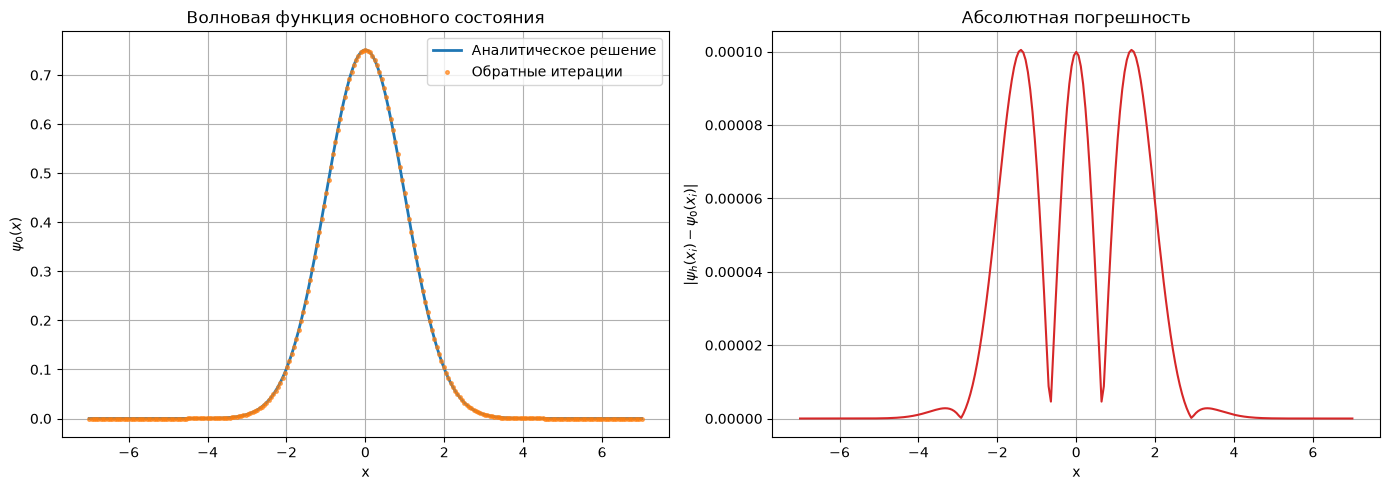

In [5]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x_fine = np.linspace(-L, L, 1000)

# Аналитическое и численное решения
axes[0].plot(
    x_fine, psi_exact(x_fine),
    label="Аналитическое решение",
    linewidth=2
)

axes[0].plot(
    x, psi_num, "o",
    markersize=2.6,
    alpha=0.65,
    label="Обратные итерации"
)

axes[0].set_title("Волновая функция основного состояния")
axes[0].set_xlabel("x")
axes[0].set_ylabel(r"$\psi_0(x)$")
axes[0].legend()

# Абсолютная погрешность
axes[1].plot(
    x, np.abs(psi_error),
    color="tab:red"
)

axes[1].set_title("Абсолютная погрешность")
axes[1].set_xlabel("x")
axes[1].set_ylabel(r"$|\psi_h(x_i)-\psi_0(x_i)|$")

plt.tight_layout()
plt.show()


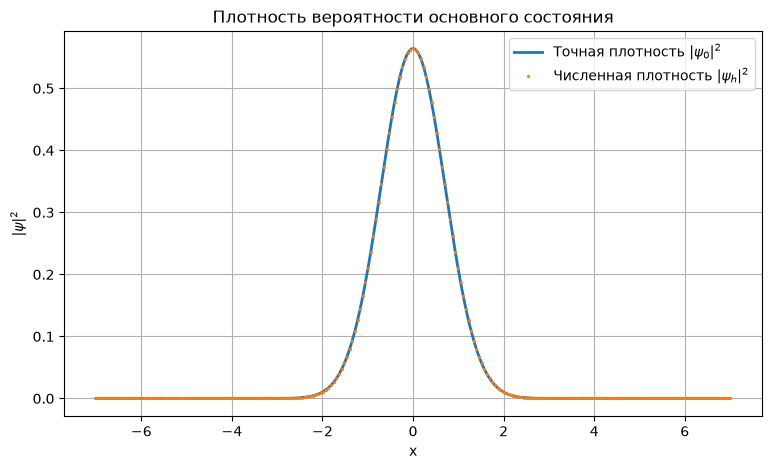

In [6]:

plt.figure(figsize=(9, 5))

plt.plot(
    x_fine,
    psi_exact(x_fine)**2,
    label=r"Точная плотность $|\psi_0|^2$",
    linewidth=2
)

plt.plot(
    x,
    psi_num**2,
    ".",
    markersize=2.5,
    label=r"Численная плотность $|\psi_h|^2$"
)

plt.xlabel("x")
plt.ylabel(r"$|\psi|^2$")
plt.title("Плотность вероятности основного состояния")
plt.legend()
plt.grid(True)
plt.show()



## 8. Независимая проверка собственных значений

Для дополнительной проверки сравним энергию, полученную методом обратных итераций, с результатом библиотечной функции `scipy.linalg.eigh_tridiagonal`.

Эта функция предназначена для вычисления собственных значений симметричной трёхдиагональной матрицы.

Библиотечный метод используется только для проверки, а основное решение получено собственной реализацией метода обратных итераций.


In [7]:

_, _, main, upper = make_hamiltonian(L, N, U)

E_ref = eigh_tridiagonal(
    main, upper,
    select="i",
    select_range=(0, 0),
    eigvals_only=True
)[0]

print(f"Энергия обратными итерациями: {E_num:.12f}")
print(f"Энергия по SciPy:             {E_ref:.12f}")
print(f"Разность методов:             {abs(E_num - E_ref):.3e}")
print(f"Ошибка относительно E0=0.5:  {abs(E_ref - E_EXACT):.3e}")


Энергия обратными итерациями: 0.499893640565
Энергия по SciPy:             0.499893640565
Разность методов:             3.147e-14
Ошибка относительно E0=0.5:  1.064e-04



## 9. Исследование сходимости итерационного метода

Исследуем, как меняется точность вычислений при увеличении количества обратных итераций.

На каждой итерации мы вычисляли энергию $E^{(k)}$ и невязку:

$$
r^{(k)}=H\psi^{(k)}-E^{(k)}\psi^{(k)}.
$$

Для оценки сходимости рассмотрим величины:

$$
\|r^{(k)}\|_h
$$

и

$$
|E^{(k)}-E_{h,0}|,
$$

где $E_{h,0}$ — минимальное собственное значение дискретной матрицы $H_h$, найденное библиотечным решателем.

Таким образом, мы исследуем сходимость именно итерационного процесса, отдельно от погрешности замены дифференциального оператора разностным.


Первые итерации:


,k,E,Невязка,Изменение ψ
0,1,1.308330,7.065728,1.279007
1,2,0.520968,0.181455,0.333596
2,3,0.501748,0.046116,0.091622
3,4,0.500081,0.014066,0.028118
4,5,0.499914,0.004524,0.009050


Последние итерации:


,k,E,Невязка,Изменение ψ
17,18,0.499894,2.783169e-09,5.567528e-09
18,19,0.499894,9.278548e-10,1.856106e-09
19,20,0.499894,3.093262e-10,6.187897e-10
20,21,0.499894,1.031263e-10,2.062925e-10
21,22,0.499894,3.437979e-11,6.877406e-11


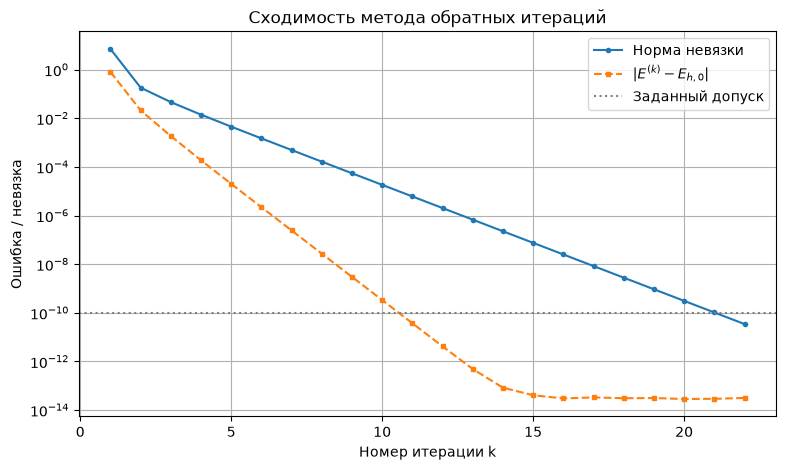

In [8]:

print("Первые итерации:")
display(history.head(5))

print("Последние итерации:")
display(history.tail(5))

plt.figure(figsize=(9, 5))

# Норма невязки
plt.semilogy(
    history["k"],
    history["Невязка"],
    "o-",
    markersize=3,
    label="Норма невязки"
)

# Ошибка энергии относительно дискретного эталона
plt.semilogy(
    history["k"],
    np.maximum(np.abs(history["E"] - E_ref), 1e-16),
    "s--",
    markersize=3,
    label=r"$|E^{(k)}-E_{h,0}|$"
)

plt.axhline(
    EPS,
    color="gray",
    linestyle=":",
    label="Заданный допуск"
)

plt.xlabel("Номер итерации k")
plt.ylabel("Ошибка / невязка")
plt.title("Сходимость метода обратных итераций")
plt.legend()
plt.grid(True)
plt.show()



## 10. Исследование порядка сходимости численного решения

Теперь исследуем, как погрешность зависит от шага сетки.

Будем фиксировать расчётный отрезок $[-L,L]$ и последовательно увеличивать число частей разбиения:

$$
N=40,\ 80,\ 160,\ 320,\ 640.
$$

При этом шаг сетки:

$$
h=\frac{2L}{N}.
$$

Для каждого $N$ вычислим приближение энергии $E_h$ и волновой функции $\psi_h(x)$.

Погрешность энергии определим как:

$$
\boxed{\varepsilon_E(h)=|E_h-E_0|}.
$$

Погрешность волновой функции в сеточной норме:

$$
\boxed{
\varepsilon_\psi(h)=
\sqrt{h\sum_{i=1}^{N-1}|\psi_i-\psi_0(x_i)|^2}
}.
$$

По результатам вычислений определим экспериментальный порядок сходимости:

$$
\boxed{
p\approx\log_2\left(\frac{\varepsilon(h)}{\varepsilon(h/2)}\right)
}.
$$

Если ошибка имеет порядок $O(h^2)$, то при уменьшении шага вдвое она должна уменьшаться приблизительно в четыре раза.

Важно учитывать, что мы заменили бесконечную область конечным отрезком. Поэтому для исследования сходимости по шагу используем достаточно большую область $[-7,7]$, на границах которой точная волновая функция практически равна нулю.


In [9]:

N_values = [40, 80, 160, 320, 640]

convergence_rows = []

for n in N_values:

    xx, hh, EE, pp, hist, ok = solve_ground_state(
        L, n, U, EPS, MAX_ITER, SEED
    )

    if not ok:
        raise RuntimeError(
            f"Обратные итерации не сошлись при N={n}"
        )

    exact = psi_exact(xx)

    # Согласуем знак собственных функций
    if hh * np.dot(pp, exact) < 0:
        pp *= -1

    energy_err = abs(EE - E_EXACT)

    wave_err = np.sqrt(
        hh * np.sum((pp - exact)**2)
    )

    convergence_rows.append([
        n, hh, EE,
        energy_err, wave_err, len(hist)
    ])

conv = pd.DataFrame(
    convergence_rows,
    columns=[
        "N",
        "h",
        "E_h",
        "Ошибка энергии",
        "Ошибка ψ (L2)",
        "Итераций"
    ]
)

# Экспериментальный порядок сходимости
conv["p энергии"] = np.nan
conv["p ψ"] = np.nan

for i in range(1, len(conv)):

    conv.loc[i, "p энергии"] = np.log2(
        conv.loc[i - 1, "Ошибка энергии"]
        / conv.loc[i, "Ошибка энергии"]
    )

    conv.loc[i, "p ψ"] = np.log2(
        conv.loc[i - 1, "Ошибка ψ (L2)"]
        / conv.loc[i, "Ошибка ψ (L2)"]
    )

display(
    conv.style.format({
        "h": "{:.6f}",
        "E_h": "{:.10f}",
        "Ошибка энергии": "{:.3e}",
        "Ошибка ψ (L2)": "{:.3e}",
        "p энергии": "{:.4f}",
        "p ψ": "{:.4f}"
    }, na_rep="—")
)


,N,h,E_h,Ошибка энергии,Ошибка ψ (L2),Итераций,p энергии,p ψ
0,40,0.350000,0.4961418689,3.858e-03,5.752e-03,23,—,—
1,80,0.175000,0.4990411263,9.589e-04,1.416e-03,20,2.0085,2.0223
2,160,0.087500,0.4997606275,2.394e-04,3.526e-04,21,2.0021,2.0055
3,320,0.043750,0.4999401784,5.982e-05,8.807e-05,23,2.0005,2.0014
4,640,0.021875,0.4999850459,1.495e-05,2.201e-05,15,2.0001,2.0003


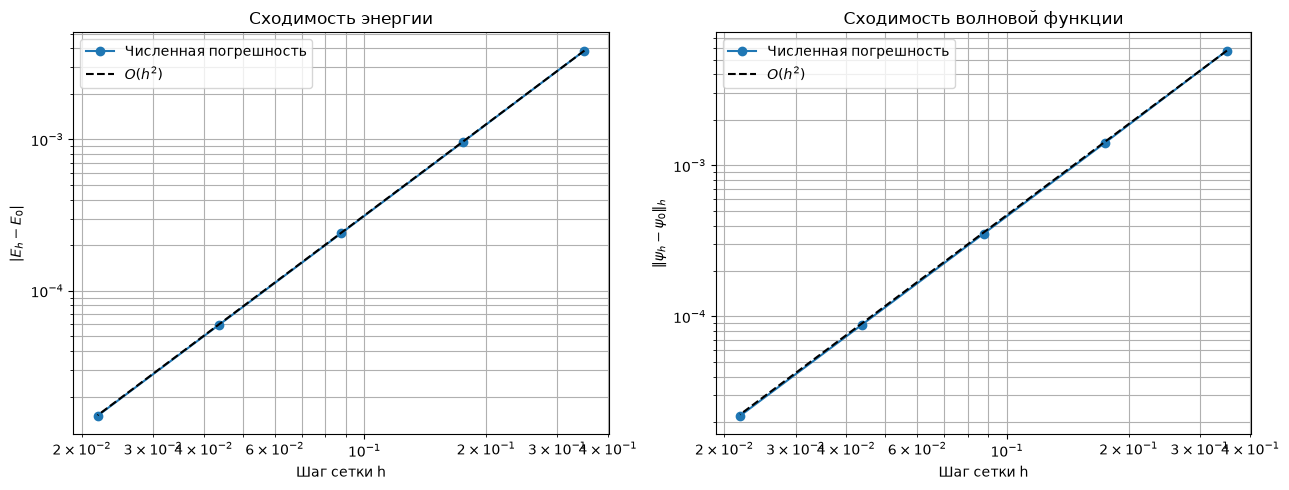

Последний порядок энергии: 2.0001
Последний порядок ψ: 2.0003


In [10]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, col, caption in [
    (
        axes[0],
        "Ошибка энергии",
        r"$|E_h-E_0|$"
    ),
    (
        axes[1],
        "Ошибка ψ (L2)",
        r"$\|\psi_h-\psi_0\|_h$"
    )
]:

    # Полученная погрешность
    ax.loglog(
        conv["h"],
        conv[col],
        "o-",
        label="Численная погрешность"
    )

    # Эталонная линия второго порядка
    reference = (
        conv[col].iloc[0]
        * (conv["h"] / conv["h"].iloc[0])**2
    )

    ax.loglog(
        conv["h"],
        reference,
        "k--",
        label=r"$O(h^2)$"
    )

    ax.set_xlabel("Шаг сетки h")
    ax.set_ylabel(caption)
    ax.legend()
    ax.grid(True, which="both")

axes[0].set_title("Сходимость энергии")
axes[1].set_title("Сходимость волновой функции")

plt.tight_layout()
plt.show()

print(
    "Последний порядок энергии:",
    f"{conv['p энергии'].iloc[-1]:.4f}"
)

print(
    "Последний порядок ψ:",
    f"{conv['p ψ'].iloc[-1]:.4f}"
)



## 11. Влияние размера расчётной области

В исходной задаче условие на волновую функцию задаётся при $|x|\to\infty$:

$$
|\psi(x)|\to0.
$$

Однако при численном решении мы вынуждены ограничивать область отрезком $[-L,L]$ и задавать:

$$
\psi(-L)=\psi(L)=0.
$$

Для слишком маленького $L$ это приближение может заметно искажать решение.

Поэтому исследуем зависимость ошибки энергии от величины $L$.

Для этого будем изменять $L$, сохраняя приблизительно одинаковый шаг сетки, чтобы уменьшить влияние дискретизации.


,L,N,h,E_h,|E_h - 0.5|
0,2.0,67,0.059701,0.537354,0.037354
1,2.5,83,0.060241,0.504847,0.004847
2,3.0,100,0.060000,0.500280,0.000280
3,4.0,133,0.060150,0.499887,0.000113
4,5.0,167,0.059880,0.499888,0.000112
5,6.0,200,0.060000,0.499887,0.000113
6,7.0,233,0.060086,0.499887,0.000113


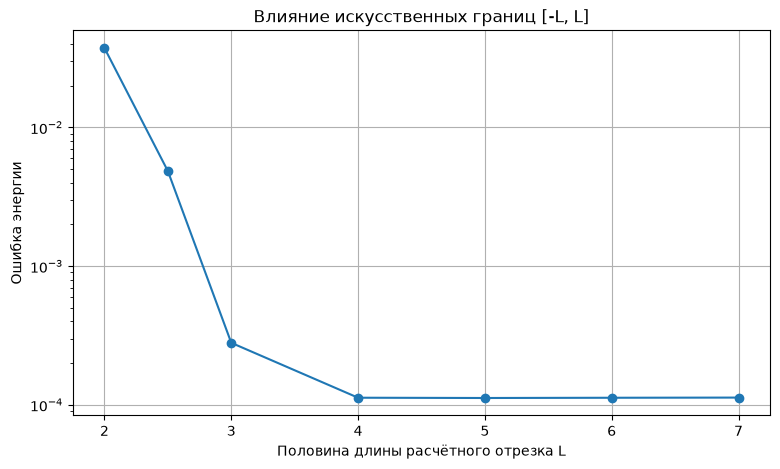

In [11]:

L_values = [2.0, 2.5, 3.0, 4.0, 5.0, 6.0, 7.0]

target_h = 0.06
length_rows = []

for ell in L_values:

    n = max(
        20,
        int(round(2 * ell / target_h))
    )

    xx, hh, EE, pp, hist, ok = solve_ground_state(
        ell, n, U, EPS, MAX_ITER, SEED
    )

    if not ok:
        raise RuntimeError(
            f"Нет сходимости для L={ell}"
        )

    length_rows.append([
        ell, n, hh, EE, abs(EE - E_EXACT)
    ])

length_df = pd.DataFrame(
    length_rows,
    columns=[
        "L", "N", "h", "E_h", "|E_h - 0.5|"
    ]
)

display(length_df)

plt.figure(figsize=(9, 5))

plt.semilogy(
    length_df["L"],
    length_df["|E_h - 0.5|"],
    "o-"
)

plt.xlabel("Половина длины расчётного отрезка L")
plt.ylabel("Ошибка энергии")
plt.title("Влияние искусственных границ [-L, L]")
plt.grid(True)
plt.show()



## 12. Дополнительный эксперимент с другим потенциалом

Для проверки универсальности реализованного алгоритма рассмотрим ещё один потенциал:

$$
U(x)=\frac{x^4}{4}.
$$

В этом случае аналитическое решение основного состояния не используется.

Однако численный алгоритм остаётся тем же: строим трёхдиагональный гамильтониан и применяем метод обратных итераций.

Проверим нормировку полученной волновой функции и малость невязки.

Этот эксперимент показывает, что реализация не ограничивается гармоническим осциллятором.


Энергия основного состояния: 0.4207636105
Итерации сошлись: True
Число итераций: 19
Невязка: 7.933e-11
Норма волновой функции: 1.000000000


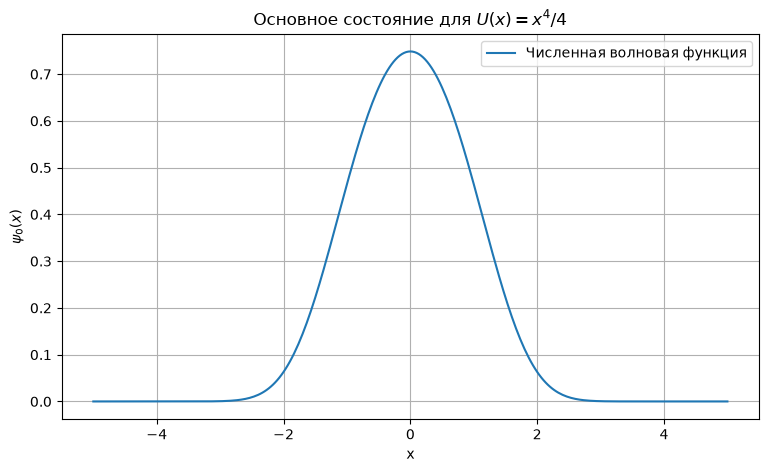

In [12]:

def U_quartic(x):
    return x**4 / 4


x_q, h_q, E_q, psi_q, hist_q, ok_q = solve_ground_state(
    5.0, 300, U_quartic, EPS, MAX_ITER, SEED
)

print(f"Энергия основного состояния: {E_q:.10f}")
print(f"Итерации сошлись: {ok_q}")
print(f"Число итераций: {len(hist_q)}")

print(
    "Невязка:",
    f"{hist_q['Невязка'].iloc[-1]:.3e}"
)

print(
    "Норма волновой функции:",
    f"{norm_h(psi_q[1:-1], h_q):.9f}"
)

plt.figure(figsize=(9, 5))

plt.plot(
    x_q,
    psi_q,
    label="Численная волновая функция"
)

plt.xlabel("x")
plt.ylabel(r"$\psi_0(x)$")
plt.title(r"Основное состояние для $U(x)=x^4/4$")
plt.legend()
plt.grid(True)
plt.show()



## 13. Выводы

В ходе лабораторной работы было рассмотрено численное решение одномерного стационарного уравнения Шрёдингера для поиска энергии и волновой функции основного состояния.

**1. Построение разностной схемы.**

На равномерной сетке была использована центральная разностная аппроксимация второй производной. В результате исходная дифференциальная задача была сведена к матричной спектральной задаче:

$$
H_h\psi=E_h\psi,
$$

где $H_h$ — симметричная трёхдиагональная матрица.

**2. Реализация метода обратных итераций.**

Для поиска минимального собственного значения гамильтониана был реализован метод обратных итераций.

Вместо явного вычисления обратной матрицы на каждой итерации решалась трёхдиагональная СЛАУ с использованием заранее вычисленного LU-разложения.

Для контроля сходимости использовалась норма невязки собственного уравнения.

**3. Проверка по аналитическому решению.**

Для гармонического осциллятора с потенциалом

$$
U(x)=\frac{x^2}{2}
$$

численно полученные энергия и волновая функция сравнивались с точными:

$$
E_0=\frac12,\qquad
\psi_0(x)=\pi^{-1/4}e^{-x^2/2}.
$$

Численные результаты согласуются с аналитическим решением. Дополнительно выполнено сравнение с библиотечным решателем собственных значений.

**4. Исследование сходимости.**

Исследована сходимость обратных итераций по номеру итерации и сходимость численного решения при уменьшении шага сетки.

По таблицам погрешностей оценён экспериментальный порядок сходимости энергии и волновой функции.

Результаты согласуются со вторым порядком аппроксимации центральной разностной схемы:

$$
\varepsilon(h)=O(h^2).
$$

**5. Влияние расчётной области.**

Показано, что выбор слишком маленького отрезка $[-L,L]$ приводит к дополнительной погрешности, связанной с заменой условия на бесконечности условиями на конечных границах.

Также алгоритм был проверен для другого потенциального поля $U(x)=x^4/4$.

**Итог.**

Метод обратных итераций позволяет эффективно находить энергию и волновую функцию основного состояния дискретного гамильтониана. Полученные численные результаты согласуются с аналитическим решением и подтверждают ожидаемые свойства используемой разностной схемы.
